# Chapitre 1 - Cours 1 : systèmes opérationnels et systèmes analytiques

Le chapitre 1 ouvre le livre sur une idée simple : en architecture de données, il n'y
a pas de bonne réponse universelle, seulement des **compromis**. Le premier, et le plus
structurant pour la suite, sépare les systèmes qui **servent les utilisateurs** (on y lit
et on y modifie quelques enregistrements à la fois) de ceux qui **analysent** l'activité
(on y parcourt des millions d'enregistrements pour en tirer des agrégats). Ce notebook
couvre l'introduction du chapitre, l'encadré *Terminology: Frontends and Backends*, la
section *Operational Versus Analytical Systems* et sa sous-section *Characterizing
Transaction Processing and Analytics*.

**Plan.**

1. Frontend, backend et infrastructure de données : pourquoi le code applicatif est
   sans état.
2. Qui utilise les données ? Les deux familles de systèmes et les métiers qui les relient.
3. Caractériser OLTP et OLAP : mesure du travail de requêtes ponctuelles et analytiques
   sur une base de ventes SQLite.
4. Pourquoi ne pas lancer l'analytique sur la base opérationnelle : simulation de
   l'interférence.
5. Requêtes figées ou ad hoc, analytique en temps réel : le compromis fraîcheur contre
   efficacité.

In [1]:
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Frontend, backend et infrastructure de données (encadré *Terminology: Frontends and Backends*)

**Le vocabulaire.** Dans une application web, le code qui s'exécute dans le navigateur
est le **frontend** ; le code côté serveur qui traite les requêtes est le **backend**.
Une application mobile joue le même rôle qu'un frontend. La difficulté se concentre
presque toujours côté backend : un frontend ne gère que les données d'un utilisateur,
alors que le backend gère celles de **tous** les utilisateurs à la fois.

Un service backend est typiquement joignable en HTTP. Il est fait de **code applicatif**
qui lit et écrit dans une ou plusieurs bases de données, et parfois dans d'autres
systèmes (caches, files de messages) : c'est ce que le livre appelle l'**infrastructure
de données**. Point essentiel : le code applicatif est en général **sans état**
(« stateless ») : une fois une requête traitée, il l'oublie. Tout ce qui doit survivre
d'une requête à l'autre vit chez le client ou dans l'infrastructure de données.

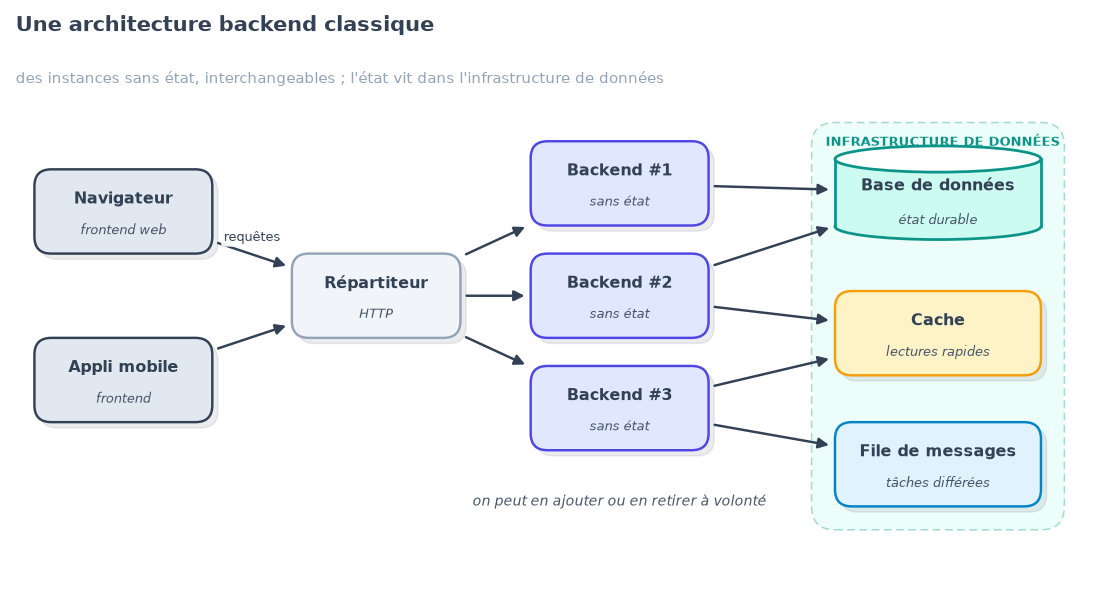

In [2]:
d = Diagram(11.5, 5.2, title="Une architecture backend classique",
            subtitle="des instances sans état, interchangeables ; l'état vit dans l'infrastructure de données")
d.box("web", 1.2, 4.0, "Navigateur", sub="frontend web", color=SLATE, w=1.9)
d.box("mob", 1.2, 2.2, "Appli mobile", sub="frontend", color=SLATE, w=1.9)
d.box("lb", 3.9, 3.1, "Répartiteur", sub="HTTP", color=GRAY, w=1.8)
d.box("b1", 6.5, 4.3, "Backend #1", sub="sans état", color=INDIGO, w=1.9)
d.box("b2", 6.5, 3.1, "Backend #2", sub="sans état", color=INDIGO, w=1.9)
d.box("b3", 6.5, 1.9, "Backend #3", sub="sans état", color=INDIGO, w=1.9)
d.box("db", 9.9, 4.2, "Base de données", sub="état durable", color=TEAL, kind="db", w=2.2, h=1.0)
d.box("cache", 9.9, 2.7, "Cache", sub="lectures rapides", color=AMBER, w=2.2)
d.box("mq", 9.9, 1.3, "File de messages", sub="tâches différées", color=SKY, w=2.2)
d.group(8.55, 0.6, 11.25, 4.95, "infrastructure de données", color=TEAL)
d.arrow("web", "lb", "requêtes")
d.arrow("mob", "lb")
for b in ("b1", "b2", "b3"):
    d.arrow("lb", b)
d.arrow("b1", "db")
d.arrow("b2", "db")
d.arrow("b2", "cache")
d.arrow("b3", "cache")
d.arrow("b3", "mq")
d.note(6.5, 0.9, "on peut en ajouter ou en retirer à volonté")
d.show()

**Pourquoi « sans état » ?** Parce que le répartiteur peut envoyer deux requêtes
successives d'un même utilisateur à deux instances différentes. Démontrons-le : un
panier d'achat est incrémenté six fois, en répartition circulaire (« round robin ») sur
trois instances. Dans la première version, chaque instance garde le panier **dans sa
mémoire** ; dans la seconde, elle le lit et l'écrit dans un stockage partagé (ici un
dictionnaire qui joue le rôle de la base).

In [3]:
class Backend:
    def __init__(self, name, shared):
        self.name, self.local, self.shared = name, {}, shared

    def add_item_local(self, user):        # état dans le processus : à éviter
        self.local[user] = self.local.get(user, 0) + 1
        return self.local[user]

    def add_item_shared(self, user):       # état dans l'infrastructure de données
        self.shared[user] = self.shared.get(user, 0) + 1
        return self.shared[user]


shared_store = {}
instances = [Backend(f"#{i + 1}", shared_store) for i in range(3)]
rows = []
for k in range(6):
    inst = instances[k % 3]                # répartition circulaire
    rows.append({"requête": k + 1, "instance": inst.name,
                 "panier vu (état local)": inst.add_item_local("alice"),
                 "panier vu (état partagé)": inst.add_item_shared("alice")})
pd.DataFrame(rows).set_index("requête")

,instance,panier vu (état local),panier vu (état partagé)
requête,,,
1,#1,1,1
2,#2,1,2
3,#3,1,3
4,#1,2,4
5,#2,2,5
6,#3,2,6


Avec l'état local, Alice voit son panier osciller entre 1 et 2 articles alors qu'elle en
a ajouté six ; et si l'instance #2 redémarre, une partie de son panier disparaît. Avec
l'état partagé, toutes les instances voient le même panier, et n'importe laquelle peut
tomber en panne ou être remplacée sans perte. C'est ce qui rend les instances
**interchangeables**, donc faciles à multiplier (chapitre 2) : la
difficulté est reportée sur l'infrastructure de données, qui est précisément le sujet du
livre.

> **À retenir.** Le frontend gère les données d'un utilisateur, le backend celles de tous.
> Le code applicatif est sans état ; l'état durable (et toute la difficulté : pannes,
> concurrence, volume) vit dans l'infrastructure de données.